In [12]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [13]:
# define file paths using new local data folder
video_path = os.path.join("data", "video_of_finger.MOV")
csv_path = os.path.join("data", "heart_beat_signal.csv")

# Open the video file
cap = cv2.VideoCapture(video_path)

# Check if the video opened successfully
if not cap.isOpened():
    print("Error: Could not open video.")
else:
    # get video properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = total_frames / fps

# display properties 
    print(f"Resolution: {width} x {height} pixels")
    print(f"Frame Rate (FPS): {fps:.2f}")
    print(f"Total Frames: {total_frames}")
    print(f"Duration: {duration:.2f} seconds")

Resolution: 1080 x 1920 pixels
Frame Rate (FPS): 29.98
Total Frames: 1852
Duration: 61.78 seconds


Single frame shape: (1920, 1080, 3)
Pixel data type: uint8
Top-left pixel (0, 0) RGB values: [170  18  14]


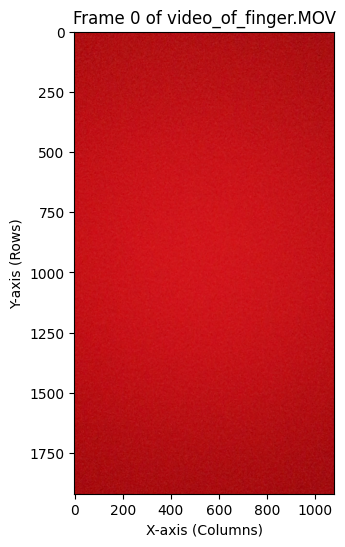

In [14]:
# Read the very first frame
ret, frame = cap.read()

if ret:
    # OpenCV loads images in BGR order; convert to RGB for Matplotlib
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    print(f"Single frame shape: {frame_rgb.shape}")
    print(f"Pixel data type: {frame_rgb.dtype}")
    print(f"Top-left pixel (0, 0) RGB values: {frame_rgb[0, 0]}")

    plt.figure(figsize=(6, 6))
    plt.imshow(frame_rgb)
    plt.title("Frame 0 of video_of_finger.MOV")
    plt.xlabel("X-axis (Columns)")
    plt.ylabel("Y-axis (Rows)")
    plt.show()

# Release the video capture so we can reset it cleanly in the next step
cap.release()

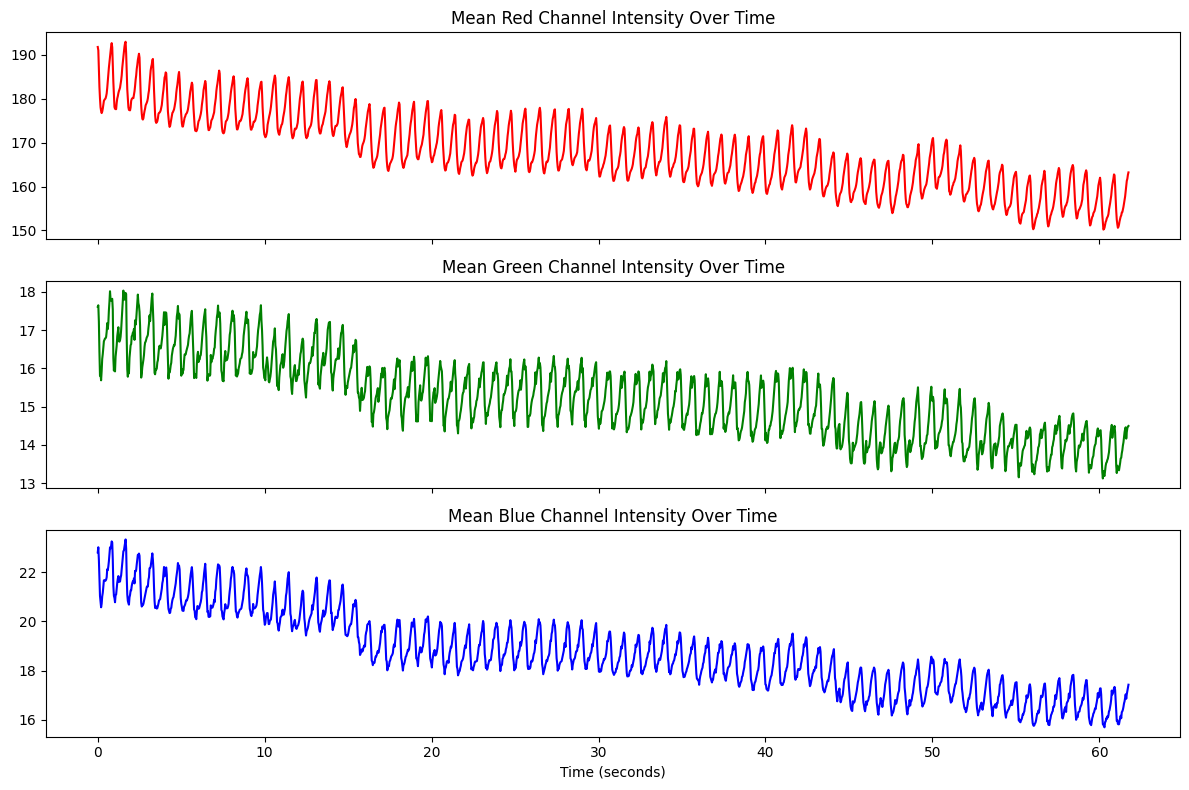

In [15]:
cap = cv2.VideoCapture(video_path)

red_signal = []
green_signal = []
blue_signal = []

while True:
    ret, frame = cap.read()
    if not ret:
        break
    
    # OpenCV channel order is BGR: 0 = Blue, 1 = Green, 2 = Red
    blue_signal.append(np.mean(frame[:, :, 0]))
    green_signal.append(np.mean(frame[:, :, 1]))
    red_signal.append(np.mean(frame[:, :, 2]))

cap.release()

# Convert lists to 1D NumPy arrays and create a time axis in seconds
red_signal = np.array(red_signal)
green_signal = np.array(green_signal)
blue_signal = np.array(blue_signal)
time = np.arange(len(red_signal)) / fps

# Plot the average intensity of each color channel over time
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(time, red_signal, color='red')
axes[0].set_title("Mean Red Channel Intensity Over Time")

axes[1].plot(time, green_signal, color='green')
axes[1].set_title("Mean Green Channel Intensity Over Time")

axes[2].plot(time, blue_signal, color='blue')
axes[2].set_title("Mean Blue Channel Intensity Over Time")
axes[2].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

       Time  Signal
0  0.033367  32.808
1  0.066733  32.793
2  0.100100  33.042
3  0.133470  32.232
4  0.166830  29.150


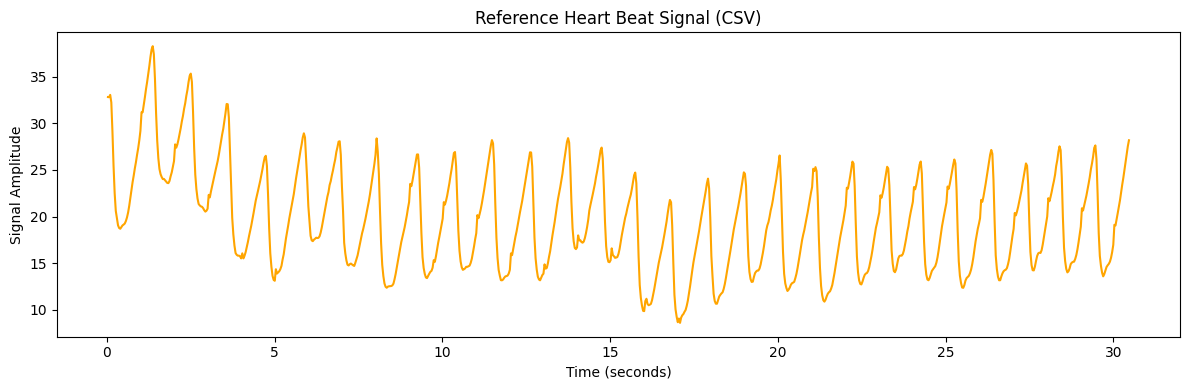

In [16]:
# Load the CSV without treating the first data row as column headers
df = pd.read_csv(csv_path, header=None, names=['Time', 'Signal'])

print(df.head())

# Plot Signal (y-axis) against Time (x-axis)
plt.figure(figsize=(12, 4))
plt.plot(df['Time'], df['Signal'], color='orange')
plt.title("Reference Heart Beat Signal (CSV)")
plt.xlabel("Time (seconds)")
plt.ylabel("Signal Amplitude")
plt.tight_layout()
plt.show()